In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [3]:
import re
import matplotlib.pyplot as plt


def extract_training_loss(log_path: str, max_epochs: int = 100) -> dict:
    """
    Trích xuất {epoch: training_loss} từ file log, với định dạng dòng:
        Epoch: 9, Training Loss: 0.0365
    """
    pattern = re.compile(r"Epoch:\s*(\d+),\s*Training Loss:\s*([\d.]+)")
    results = {}

    with open(log_path, "r", encoding="utf-8") as f:
        for line in f:
            match = pattern.search(line)
            if match:
                epoch = int(match.group(1))
                loss = float(match.group(2))
                if epoch <= max_epochs:
                    results[epoch] = loss

    return dict(sorted(results.items()))


def extract_multiple_logs(log_paths: dict, max_epochs: int = 100) -> dict:
    """log_paths: {tên_hiển_thị: đường_dẫn_file}"""
    return {
        name: extract_training_loss(path, max_epochs=max_epochs)
        for name, path in log_paths.items()
    }

In [6]:
log_paths = {
    "ResCNN-Biretention-SwiGLU": "../save/CAN-ML_models/conv-biretnet-swiglu/conv-biretnet-swiglu_CAN-ML_1st-running_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/083126_124047/log",       
    "ResCNN-Transformer": "../save/CAN-ML_models/ResCNN-Transformer/ResCNN-Transformer_CAN-ML_seed=1+1st-running_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/091426_145903/log",               
}

results = extract_multiple_logs(log_paths, max_epochs=100)

# Kiểm tra nhanh
for name, losses in results.items():
    print(f"{name}: {len(losses)} epoch trích xuất được, "
          f"loss epoch 1 = {list(losses.values())[0]:.4f}, "
          f"loss epoch cuối = {list(losses.values())[-1]:.4f}")

ResCNN-Biretention-SwiGLU: 100 epoch trích xuất được, loss epoch 1 = 0.2454, loss epoch cuối = 0.0069
ResCNN-Transformer: 100 epoch trích xuất được, loss epoch 1 = 0.2530, loss epoch cuối = 0.0111


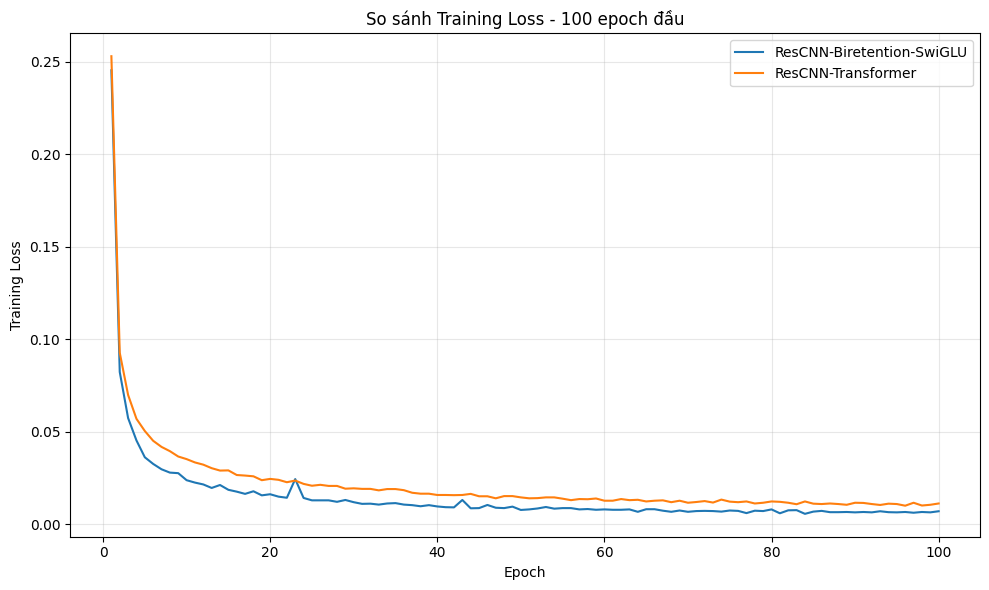

In [7]:
plt.figure(figsize=(10, 6))

for name, losses in results.items():
    epochs = list(losses.keys())
    loss_values = list(losses.values())
    plt.plot(epochs, loss_values, label=name, linewidth=1.5)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("So sánh Training Loss - 100 epoch đầu")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

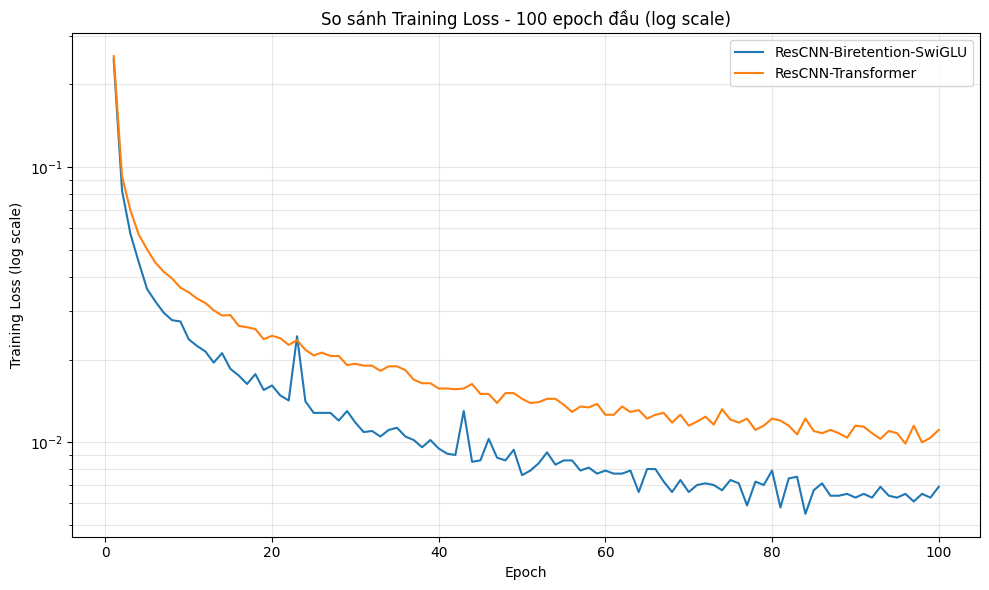

In [8]:
plt.figure(figsize=(10, 6))

for name, losses in results.items():
    epochs = list(losses.keys())
    loss_values = list(losses.values())
    plt.plot(epochs, loss_values, label=name, linewidth=1.5)

plt.yscale("log")   # trục Y dạng log — hữu ích khi loss giảm mạnh (0.25 → 0.01)
plt.xlabel("Epoch")
plt.ylabel("Training Loss (log scale)")
plt.title("So sánh Training Loss - 100 epoch đầu (log scale)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()